# Zero-R et Naïve Bayes, expliqués et évalués

Exécuter d'abord le notebook 01. Ce notebook propose un protocole temporel à harmoniser
avec celui du responsable du prétraitement. Il ne remplace pas la décision commune.
**Aucun score de test 2025 n'est calculé.** Le réglage utilise cinq plis dans 2012-2023.
L'année 2024 sert ensuite de validation séparée.

Ces résultats décrivent une classification rétrospective sur des exemples sélectionnés,
pas un système opérationnel de prévision des incendies.

## 1. Retrouver le projet et les données nettoyées
Les NaN sont encore présents : c'est volontaire. L'imputation sera ajustée dans chaque pli.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Trouver la racine, que le notebook soit ouvert depuis la racine ou notebooks/.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/cleaning_guide.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Placer notebooks/ et src/ dans le même dossier de projet.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.cleaning_guide import clean_data
for folder in ['data/processed', 'results', 'figures', 'models']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 12)
pd.set_option('display.width', 130)
print('Dossier du projet trouvé.')

path = ROOT / 'data/processed/dataset_clean.csv'
if not path.exists():
    raise FileNotFoundError('Exécuter le notebook 01 avant celui-ci.')
df = pd.read_csv(path, parse_dates=['date'])
train = df.loc[df['split'].eq('train')].sort_values(['date', 'cell_id']).reset_index(drop=True)
valid = df.loc[df['split'].eq('val')].copy()
print('Train :', len(train), 'lignes ; validation :', len(valid), 'lignes.')

Dossier du projet trouvé.
Train : 104979 lignes ; validation : 8423 lignes.


## 2. Séparer X et y
`X` contient les informations données au modèle ; `y` contient la réponse `label`.
On propose 24 variables numériques. `doy` représente la position dans la saison : il peut être utile,
il n'est pas automatiquement inutile parce qu'il se calcule à partir de la date.

`cell_id`, `lat`, `lon`, `date`, `year` et `split` restent des métadonnées dans cette première expérience.
Les coordonnées ne sont pas une fuite automatique ; leur inclusion demanderait une justification
et une validation spatiale adaptée. Les trois fuites du jour sont déjà retirées.

`days_since_last_fire` est provisoirement exclue en attendant la confirmation de son historique
et du codage 9999. `ndvi_normal` et `ndvi_anomaly` sont provisoirement exclues en attendant
de vérifier la période utilisée pour calculer la normale : elle ne doit pas utiliser le futur.
Les variables NDVI conservées nécessitent aussi une confirmation de leur disponibilité à la date cible.
Ces exclusions de prudence sont des choix de ce guide, pas des défauts démontrés de ces colonnes.

In [2]:
FEATURES = [
    'temp_max', 'temp_min', 'temp_mean', 'rh_min', 'rh_mean',
    'wind_max', 'wind_mean', 'precip_sum', 'vpd_max',
    'precip_7d', 'precip_30d', 'days_since_rain_1mm',
    'temp_max_7d_mean', 'rh_min_7d_mean',
    'ffmc', 'dmc', 'dc', 'isi', 'bui', 'fwi',
    'ndvi', 'ndvi_change_32d', 'ndvi_stale_days', 'doy'
]
assert not set(FEATURES) & {'label', 'sample_kind', 'n_detections', 'max_frp', 'split'}
X_train, y_train = train[FEATURES], train['label'].astype(int)
X_val, y_val = valid[FEATURES], valid['label'].astype(int)
print('Variables d’entrée :', len(FEATURES))
print('Cible :', sorted(y_train.unique().tolist()))

Variables d’entrée : 24
Cible : [0, 1]


## 3. Construire les cinq plis temporels
Un pli est un entraînement sur une période suivi d'une évaluation sur une période distincte.
Exemple : apprendre sur 2012-2018 et valider sur 2019. Puis apprendre sur 2012-2019 et valider sur 2020.
Les cinq validations couvrent 2019, 2020, 2021, 2022 et 2023.

Toutes les lignes d'une même année restent du même côté. Le passé précède toujours la validation.
Les mêmes zones peuvent apparaître à plusieurs années : ce protocole vise les années futures
sur le territoire représenté, pas une généralisation démontrée à des zones jamais vues.
Le sujet demande au moins cinq plis ; justifier cette adaptation chronologique avec l'équipe.

In [3]:
cv_splits = []
fold_rows = []
for year in [2019, 2020, 2021, 2022, 2023]:
    fit_idx = np.flatnonzero(train['year'].lt(year).to_numpy())
    eval_idx = np.flatnonzero(train['year'].eq(year).to_numpy())
    assert train.iloc[fit_idx]['date'].max() < train.iloc[eval_idx]['date'].min()
    assert y_train.iloc[fit_idx].nunique() == y_train.iloc[eval_idx].nunique() == 2
    cv_splits.append((fit_idx, eval_idx))
    fold_rows.append({'train_fin': year - 1, 'validation': year, 'n_train': len(fit_idx), 'n_validation': len(eval_idx)})
print(pd.DataFrame(fold_rows).to_string(index=False))
pd.DataFrame(fold_rows).to_csv(ROOT / 'results/plis_temporels.csv', index=False)

 train_fin  validation  n_train  n_validation
      2018        2019    61948          8723
      2019        2020    70671          8724
      2020        2021    79395          8602
      2021        2022    87997          8602
      2022        2023    96599          8380


## 4. Choisir les métriques avant de régler le modèle
Proposition : **F1 de la classe 1** comme critère principal, à partager avec l'équipe.

- Accuracy : proportion de toutes les réponses correctes.
- Précision : parmi les alertes, proportion réellement étiquetée 1.
- Rappel : parmi les vrais positifs, proportion détectée.
- F1 : compromis entre précision et rappel.
- ROC-AUC : capacité à classer les positifs au-dessus des négatifs, en variant le seuil.
- Average precision : résumé de la courbe précision-rappel, sensible à la fréquence des positifs.

`zero_division=0` fixe la convention de score lorsqu'un modèle ne prédit aucun positif.
Il faut l'expliquer : une précision définie ainsi à zéro n'indique pas des alertes toutes fausses,
puisque Zero-R ne produit aucune alerte.

In [4]:
from sklearn.metrics import (make_scorer, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix)
from sklearn.model_selection import cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
SCORING = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': 'roc_auc',
    'average_precision': 'average_precision'
}
print('Métrique de sélection proposée : F1 de la classe 1.')

Métrique de sélection proposée : F1 de la classe 1.


## 5. Zero-R : la référence minimale
Zero-R apprend uniquement la classe majoritaire de l'entraînement et la prédit pour tous les exemples.
Il n'utilise aucune relation entre météo et incendie. Il ne nécessite pas de réglage.
Une accuracy élevée peut donc coexister avec un rappel incendie nul.
L'imputation ci-dessous n'est pas nécessaire à Zero-R ; elle conserve une structure de pipeline uniforme.

In [5]:
zero_r = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', DummyClassifier(strategy='most_frequent'))
])
zero_cv = cross_validate(zero_r, X_train, y_train, cv=cv_splits,
                         scoring=SCORING, n_jobs=1, error_score='raise')
zero_r.fit(X_train, y_train)
print('Classe toujours prédite :', int(zero_r.predict(X_val.iloc[:1])[0]))
print('Accuracy CV moyenne :', zero_cv['test_accuracy'].mean())
print('Rappel CV moyen :', zero_cv['test_recall'].mean())

Classe toujours prédite : 0
Accuracy CV moyenne : 0.7747319996008082
Rappel CV moyen : 0.0


## 6. Naïve Bayes : apprendre les profils des deux classes
GaussianNB estime une moyenne et une variance par variable et par classe. Il utilise
une distribution gaussienne pour chaque variable, conditionnellement à la classe.
Il combine les informations en supposant leur indépendance conditionnelle.
Les relations entre températures et indices FWI rendent cette hypothèse imparfaite ici.

GaussianNB accepte des variables numériques continues, y compris négatives. MultinomialNB
correspond plutôt à des comptes non négatifs ; BernoulliNB à des variables binaires.
GaussianNB reste un modèle de comparaison, même si plusieurs distributions ne sont pas gaussiennes.

Le pipeline apprend la médiane et la standardisation **dans chaque entraînement**.
La standardisation n'est pas une obligation théorique de GaussianNB, mais rend ici
la régularisation des variances moins dépendante des différences d'échelle.
`var_smoothing` stabilise ces variances : ce n'est pas le lissage de Laplace `alpha`.

In [6]:
nb_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', GaussianNB())
])
grid = {'model__var_smoothing': [1e-12, 1e-10, 1e-9, 1e-8, 1e-6, 1e-4, 1e-2]}
search = GridSearchCV(nb_pipeline, grid, scoring=SCORING, refit='f1', cv=cv_splits,
                      n_jobs=1, return_train_score=True, error_score='raise')
search.fit(X_train, y_train)
best_nb = search.best_estimator_
print('Configurations :', len(grid['model__var_smoothing']), '; plis :', len(cv_splits))
print('Paramètre retenu :', search.best_params_)
print('F1 CV retenu :', search.best_score_)
tuning = pd.DataFrame(search.cv_results_)
print(tuning[['param_model__var_smoothing', 'mean_train_f1', 'mean_test_f1', 'std_test_f1']].to_string(index=False))
tuning.to_csv(ROOT / 'results/recherche_naive_bayes.csv', index=False)

Configurations : 7 ; plis : 5
Paramètre retenu : {'model__var_smoothing': 0.01}
F1 CV retenu : 0.40984143400672945
 param_model__var_smoothing  mean_train_f1  mean_test_f1  std_test_f1
               1.000000e-12       0.557835      0.409787     0.130015
               1.000000e-10       0.557835      0.409787     0.130015
               1.000000e-09       0.557835      0.409787     0.130015
               1.000000e-08       0.557835      0.409787     0.130015
               1.000000e-06       0.557835      0.409787     0.130015
               1.000000e-04       0.557833      0.409787     0.130015
               1.000000e-02       0.557934      0.409841     0.129879


## 7. Comparer avec des résultats réellement calculés
Les colonnes `cv_*` résument 2019-2023 ; `val2024_*` décrivent l'année 2024 séparément.
Le score CV du meilleur réglage a servi à sélectionner ce réglage : il n'est pas une mesure finale indépendante.
Les probabilités servent au calcul de ROC-AUC ; on n'utilise pas seulement les classes prédites.

Une probabilité de GaussianNB peut être mal calibrée. Avec des négatifs sélectionnés,
ne l'affiche pas comme une probabilité réelle d'incendie sur le territoire.

In [7]:
models = {'Zero-R': zero_r, 'GaussianNB': best_nb}
result_rows = []
val_scores = {}
for name, model in models.items():
    predicted = model.predict(X_val)
    positive_column = list(model.classes_).index(1)
    scores = model.predict_proba(X_val)[:, positive_column]
    val_scores[name] = scores
    row = {'model': name, 'n_features': len(FEATURES), 'validation': '2024',
           'val2024_accuracy': accuracy_score(y_val, predicted),
           'val2024_precision': precision_score(y_val, predicted, zero_division=0),
           'val2024_recall': recall_score(y_val, predicted, zero_division=0),
           'val2024_f1': f1_score(y_val, predicted, zero_division=0),
           'val2024_roc_auc': roc_auc_score(y_val, scores),
           'val2024_average_precision': average_precision_score(y_val, scores)}
    for metric in SCORING:
        if name == 'Zero-R':
            values = zero_cv['test_' + metric]
            row['cv_' + metric + '_mean'] = float(values.mean())
            row['cv_' + metric + '_std'] = float(values.std(ddof=0))
        else:
            row['cv_' + metric + '_mean'] = float(tuning.loc[search.best_index_, 'mean_test_' + metric])
            row['cv_' + metric + '_std'] = float(tuning.loc[search.best_index_, 'std_test_' + metric])
    tn, fp, fn, tp = confusion_matrix(y_val, predicted, labels=[0, 1]).ravel()
    row.update(tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))
    result_rows.append(row)
results = pd.DataFrame(result_rows)
print(results[['model', 'cv_f1_mean', 'cv_f1_std', 'val2024_accuracy', 'val2024_precision',
               'val2024_recall', 'val2024_f1', 'val2024_roc_auc']].round(4).to_string(index=False))
results.to_csv(ROOT / 'results/resultats_zeror_nb_validation.csv', index=False)

     model  cv_f1_mean  cv_f1_std  val2024_accuracy  val2024_precision  val2024_recall  val2024_f1  val2024_roc_auc
    Zero-R      0.0000     0.0000            0.9237             0.0000          0.0000      0.0000           0.5000
GaussianNB      0.4098     0.1299            0.4811             0.1005          0.7294      0.1767           0.6299


## Lire les résultats obtenus sur 2024

| Modèle | Accuracy | Précision classe 1 | Rappel classe 1 | F1 classe 1 | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Zero-R | 92,37 % | 0 (convention) | 0 % | 0 | 0,500 |
| GaussianNB | 48,11 % | 10,05 % | 72,94 % | 0,177 | 0,630 |

Zero-R obtient beaucoup de réponses correctes en choisissant toujours 0, mais rate les **643** exemples
positifs de validation. GaussianNB en retrouve **469**, en rate **174** et produit **4 197 faux positifs**.
La majorité de ses alertes ne correspond donc pas à une détection étiquetée.

Son F1 moyen sur les cinq plis vaut environ **0,410**, avec un écart-type de **0,130**, contre **0,177**
sur 2024. Cela montre une performance moins bonne sur cette année. Les changements entre années,
le déséquilibre des classes, les distributions et les hypothèses approximatives de GaussianNB
sont des pistes d’analyse ; ces scores ne permettent pas d’en attribuer la cause avec certitude.
Ce résultat de développement reste à comparer aux quatre autres modèles avec un protocole commun.
On ne modifie pas le test final 2025 pour masquer cette difficulté.


## 8. Lire les erreurs et les courbes ROC
Les faux négatifs sont des détections présentes dans les étiquettes mais ratées par le modèle.
Les faux positifs sont des alertes sur des exemples étiquetés négatifs.
La matrice est organisée avec la vérité en ligne et la prédiction en colonne.
Zero-R prédit un score constant : sa courbe ROC suit la diagonale, avec AUC = 0,5.

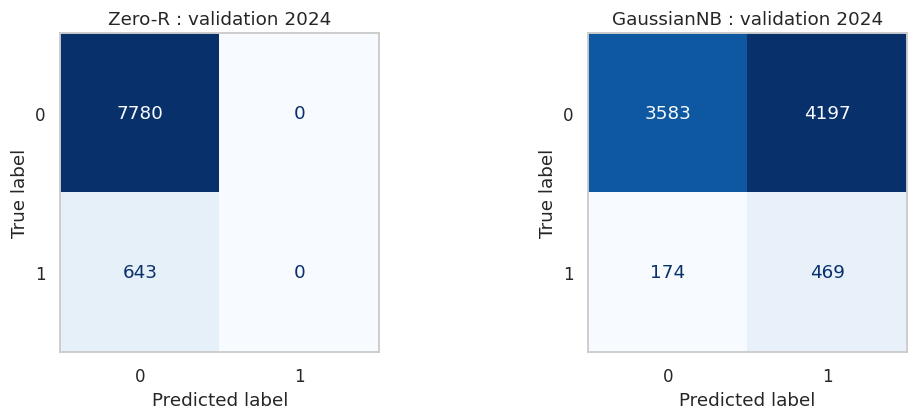

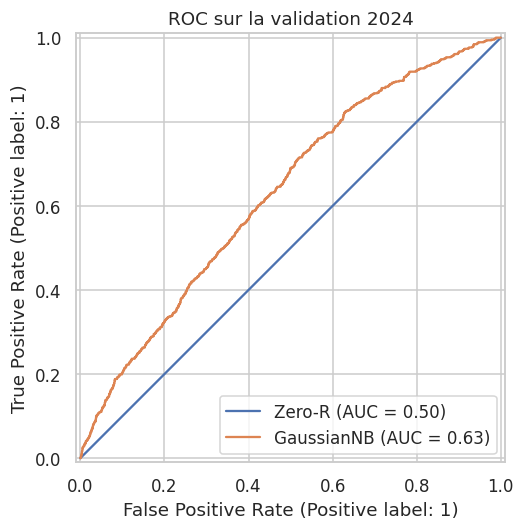

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for (name, model), ax in zip(models.items(), axes):
    ConfusionMatrixDisplay.from_predictions(y_val, model.predict(X_val), labels=[0, 1],
                                             colorbar=False, ax=ax, cmap='Blues')
    ax.set_title(name + ' : validation 2024')
    ax.grid(False)
fig.tight_layout(); fig.savefig(ROOT / 'figures/confusions_validation.png', dpi=150); plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
for name, scores in val_scores.items():
    RocCurveDisplay.from_predictions(y_val, scores, name=name, ax=ax)
ax.set_title('ROC sur la validation 2024')
fig.tight_layout(); fig.savefig(ROOT / 'figures/roc_validation.png', dpi=150); plt.show()

## 9. Sauvegarder et vérifier les pipelines
`joblib.dump` conserve l'imputation, la standardisation éventuelle et le modèle ensemble.
La vérification de rechargement contrôle que les prédictions sont identiques après sauvegarde.
Ne recharge que des fichiers joblib provenant d'une source de confiance.
Les fichiers produits ici sont entraînés sur 2012-2023 et restent des modèles de développement.

In [9]:
import joblib
import sklearn
joblib.dump(zero_r, ROOT / 'models/zeror_developpement.joblib')
joblib.dump(best_nb, ROOT / 'models/naive_bayes_developpement.joblib')
reloaded = joblib.load(ROOT / 'models/naive_bayes_developpement.joblib')
assert np.array_equal(reloaded.predict(X_val.iloc[:50]), best_nb.predict(X_val.iloc[:50]))
protocol = {'statut': 'proposition_a_harmoniser', 'train': '2012-2023', 'validation': '2024',
            'test_reserve': '2025', 'cv_annees_validation': [2019, 2020, 2021, 2022, 2023],
            'metrique_principale': 'f1_classe_1', 'features': FEATURES,
            'best_params': search.best_params_, 'sklearn_version': sklearn.__version__}
(ROOT / 'results/protocole_propose.json').write_text(json.dumps(protocol, ensure_ascii=False, indent=2), encoding='utf-8')
print('Pipelines enregistrés et rechargement vérifié. Aucun score calculé sur 2025.')

Pipelines enregistrés et rechargement vérifié. Aucun score calculé sur 2025.


## 10. Ce qu'il reste à faire avec l'équipe

Comparer les six modèles avec les mêmes plis, cible, entrées et métriques. Si le protocole commun
diffère de cette proposition, relancer les expériences selon ce protocole, sans mélanger leurs résultats.
Choisir les réglages à partir de l'entraînement et de la validation, puis figer les décisions.
Décider si le réentraînement final inclut 2024 et appliquer la même règle à tous.
Ensuite seulement, calculer les performances finales sur 2025 et les conserver dans un tableau distinct.
Un résultat 2024 ne doit jamais être renommé « test final ».

Dans ton rapport, expliquer Zero-R, GaussianNB, son hypothèse d'indépendance, la grille de sept valeurs,
le protocole temporel, les écarts entre plis et validation, les faux positifs et faux négatifs.
Ne réutilise pas le test pour améliorer le modèle après avoir vu son score.

Documentation : [Naïve Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html),
[GaussianNB et var_smoothing](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html),
[Validation croisée](https://scikit-learn.org/stable/modules/cross_validation.html),
[Fuites et pipelines](https://scikit-learn.org/stable/common_pitfalls.html).